In [2]:
import pandas as pd

In [6]:
upi_transaction = pd.read_csv('upi_transactions_10000.csv')

In [7]:
upi_transaction

,transaction_id,timestamp,sender_upi_id,receiver_upi_id,amount,transaction_type,hour_of_day,device_type,sender_bank,sender_city,receiver_city,is_new_receiver,receiver_account_age_days,sender_txn_count_24h,sender_avg_amount,failed_attempts_before,is_fraud
0,TXN009954,2026-01-06 15:42:41,user1806@okhdfcbank,user1140@oksbi,2587.27,P2M,15,Android,ICICI,Jaipur,Kolkata,0,1660,1,2124.66,0,0
1,TXN003851,2026-03-15 11:28:53,user1462@paytm,user0340@paytm,426.40,collect_request,11,Android,PNB,Mumbai,Mumbai,1,949,1,252.57,0,0
2,TXN004963,2026-03-11 03:48:09,user1615@okaxis,user1206@okaxis,1639.92,P2M,3,iOS,SBI,Delhi,Kolkata,1,15,8,262.50,3,1
3,TXN003887,2026-04-25 13:31:19,user1353@okaxis,user1173@ybl,109.70,QR_scan,13,iOS,SBI,Bengaluru,Bengaluru,0,1927,2,234.35,0,0
4,TXN005438,2026-04-22 06:15:11,user1455@okhdfcbank,user0064@oksbi,264.99,P2M,6,Android,Canara,Pune,Pune,0,2657,0,459.22,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,TXN002896,2026-02-22 18:45:31,user1313@okaxis,user0277@paytm,531.65,QR_scan,18,Android,ICICI,Bengaluru,Bengaluru,0,668,1,547.31,1,0
9996,TXN007814,2026-01-03 00:16:28,user1183@okaxis,user1746@oksbi,27373.44,P2P,0,Web,PNB,Pune,Kolkata,1,25,17,3238.61,2,1
9997,TXN000906,2026-02-06 14:44:11,user0257@oksbi,user0767@oksbi,68.74,P2P,14,Android,ICICI,Hyderabad,Delhi,0,2110,2,85.83,0,0
9998,TXN005193,2026-03-23 14:29:32,user0741@paytm,user0997@paytm,170.15,P2M,14,Android,SBI,Jaipur,Jaipur,0,1930,1,493.48,0,0


In [8]:
upi_transaction.shape

(10000, 17)

In [9]:
upi_transaction.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   transaction_id             10000 non-null  str    
 1   timestamp                  10000 non-null  str    
 2   sender_upi_id              10000 non-null  str    
 3   receiver_upi_id            10000 non-null  str    
 4   amount                     10000 non-null  float64
 5   transaction_type           10000 non-null  str    
 6   hour_of_day                10000 non-null  int64  
 7   device_type                10000 non-null  str    
 8   sender_bank                10000 non-null  str    
 9   sender_city                10000 non-null  str    
 10  receiver_city              10000 non-null  str    
 11  is_new_receiver            10000 non-null  int64  
 12  receiver_account_age_days  10000 non-null  int64  
 13  sender_txn_count_24h       10000 non-null  int64  
 14  se

In [10]:
upi_transaction['is_fraud'].value_counts()

is_fraud
0    9700
1     300
Name: count, dtype: int64

In [11]:
upi_transaction['is_fraud'].value_counts(normalize=True) * 100

is_fraud
0    97.0
1     3.0
Name: proportion, dtype: float64

In [12]:
upi_transaction.groupby('transaction_type')['is_fraud'].mean() * 100

transaction_type
P2M                 0.355962
P2P                 1.426307
QR_scan             7.951807
collect_request    30.617284
Name: is_fraud, dtype: float64

In [13]:
upi_transaction.groupby('device_type')['is_fraud'].mean() * 100

device_type
Android    2.334348
Web        9.709619
iOS        1.599200
Name: is_fraud, dtype: float64

In [14]:
upi_transaction.groupby('is_fraud')[['amount', 'sender_txn_count_24h', 'failed_attempts_before', 'receiver_account_age_days']].mean()

,amount,sender_txn_count_24h,failed_attempts_before,receiver_account_age_days
is_fraud,,,,
0,730.756116,1.506804,0.091856,1519.326598
1,18737.965033,11.836667,3.116667,57.910000


Matplotlib is building the font cache; this may take a moment.


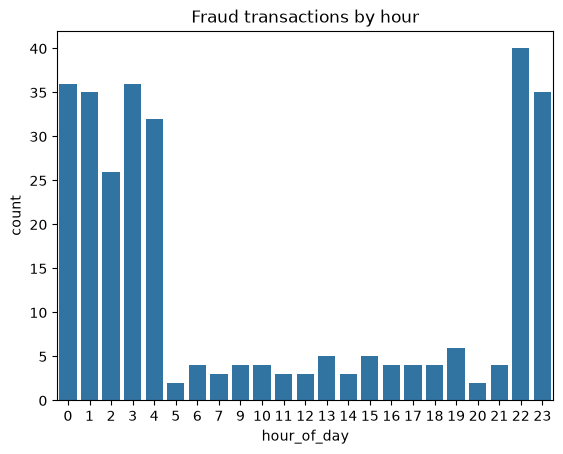

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Fraud count by hour
fraud = upi_transaction[upi_transaction['is_fraud'] == 1]
sns.countplot(x='hour_of_day', data=fraud)
plt.title('Fraud transactions by hour')
plt.show()

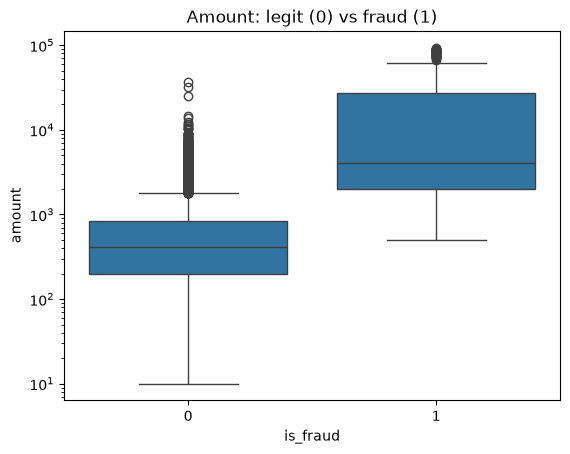

In [16]:
# Amount distribution (log scale because a few amounts are huge)
sns.boxplot(x='is_fraud', y='amount', data=upi_transaction)
plt.yscale('log')
plt.title('Amount: legit (0) vs fraud (1)')
plt.show()

In [18]:
df = upi_transaction.copy()

# Convert timestamp to a real datetime and sort by time
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)

# 1. How big is this amount compared to the sender's normal amount?
df['amount_ratio'] = df['amount'] / (df['sender_avg_amount'] + 1)

# 2. Is it a late-night transaction (10pm to 4am)?
df['is_night'] = df['hour_of_day'].apply(lambda h: 1 if (h >= 22 or h <= 4) else 0)

# 3. Is the money going to a different city?
df['is_cross_city'] = (df['sender_city'] != df['receiver_city']).astype(int)

# 4. Is the receiver account very new? (under 30 days)
df['is_new_account'] = (df['receiver_account_age_days'] < 30).astype(int)

# 5. Day of week
df['day_of_week'] = df['timestamp'].dt.day_of_week

In [19]:
df.groupby('is_fraud')[['amount_ratio', 'is_night', 'is_cross_city', 'is_new_account']].mean()

,amount_ratio,is_night,is_cross_city,is_new_account
is_fraud,,,,
0,1.284475,0.099381,0.177629,0.000000
1,57.603916,0.800000,0.886667,0.793333


In [20]:
features = ['amount', 'amount_ratio', 'hour_of_day', 'is_night', 'is_cross_city',
            'is_new_receiver', 'is_new_account', 'receiver_account_age_days',
            'sender_txn_count_24h', 'sender_avg_amount', 'failed_attempts_before',
            'day_of_week', 'transaction_type', 'device_type']

X = df[features]
y = df['is_fraud']

# Convert text categories into 0/1 columns
X = pd.get_dummies(X, columns=['transaction_type', 'device_type'], drop_first=True)

In [21]:
split = int(len(df) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print(X_train.shape, X_test.shape)
print("Fraud in train:", y_train.sum(), "| Fraud in test:", y_test.sum())

(8000, 17) (2000, 17)
Fraud in train: 245 | Fraud in test: 55


In [22]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
pred = dummy.predict(X_test)

print("Accuracy:", (pred == y_test).mean())
print(classification_report(y_test, pred, zero_division=0))

Accuracy: 0.9725
              precision    recall  f1-score   support

           0       0.97      1.00      0.99      1945
           1       0.00      0.00      0.00        55

    accuracy                           0.97      2000
   macro avg       0.49      0.50      0.49      2000
weighted avg       0.95      0.97      0.96      2000



In [24]:
def evaluate(model, name):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    print(f"===== {name} =====")
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, digits=3))
    print("PR-AUC:", round(average_precision_score(y_test, prob), 3))

In [25]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=1000)
)
logreg.fit(X_train, y_train)
evaluate(logreg, "Logistic Regression")

===== Logistic Regression =====
[[1945    0]
 [   0   55]]
              precision    recall  f1-score   support

           0      1.000     1.000     1.000      1945
           1      1.000     1.000     1.000        55

    accuracy                          1.000      2000
   macro avg      1.000     1.000     1.000      2000
weighted avg      1.000     1.000     1.000      2000

PR-AUC: 1.0


In [26]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, class_weight='balanced',
                            random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
evaluate(rf, "Random Forest")

===== Random Forest =====
[[1945    0]
 [   0   55]]
              precision    recall  f1-score   support

           0      1.000     1.000     1.000      1945
           1      1.000     1.000     1.000        55

    accuracy                          1.000      2000
   macro avg      1.000     1.000     1.000      2000
weighted avg      1.000     1.000     1.000      2000

PR-AUC: 1.0


In [27]:
import pandas as pd
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
importances.sort_values(ascending=False).head(10)

sender_txn_count_24h         0.278541
failed_attempts_before       0.220207
amount_ratio                 0.168337
receiver_account_age_days    0.114550
is_new_account               0.078025
amount                       0.042799
is_new_receiver              0.040592
is_cross_city                0.028732
is_night                     0.014260
hour_of_day                  0.010118
dtype: float64

In [28]:
cols_to_drop = ['amount', 'amount_ratio', 'sender_txn_count_24h', 'failed_attempts_before']
X_train_h = X_train.drop(columns=cols_to_drop)
X_test_h  = X_test.drop(columns=cols_to_drop)

rf2 = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1)
rf2.fit(X_train_h, y_train)

from sklearn.metrics import classification_report, average_precision_score
pred = rf2.predict(X_test_h)
print(classification_report(y_test, pred, digits=3))
print("PR-AUC:", average_precision_score(y_test, rf2.predict_proba(X_test_h)[:, 1]))

              precision    recall  f1-score   support

           0      0.998     0.999     0.999      1945
           1      0.981     0.945     0.963        55

    accuracy                          0.998      2000
   macro avg      0.990     0.972     0.981      2000
weighted avg      0.998     0.998     0.998      2000

PR-AUC: 0.9894105909282284


In [29]:
import joblib

def build_features(d):
    d = d.copy()
    d['amount_ratio']   = d['amount'] / (d['sender_avg_amount'] + 1)
    d['is_night']       = d['hour_of_day'].apply(lambda h: 1 if (h >= 22 or h <= 4) else 0)
    d['is_cross_city']  = (d['sender_city'] != d['receiver_city']).astype(int)
    d['is_new_account'] = (d['receiver_account_age_days'] < 30).astype(int)
    return d

FEATURES = ['amount', 'amount_ratio', 'hour_of_day', 'is_night', 'is_cross_city',
            'is_new_receiver', 'is_new_account', 'receiver_account_age_days',
            'sender_txn_count_24h', 'sender_avg_amount', 'failed_attempts_before',
            'day_of_week', 'transaction_type', 'device_type']

def prepare(d, columns):
    d = build_features(d)[FEATURES]
    d = pd.get_dummies(d, columns=['transaction_type', 'device_type'])
    return d.reindex(columns=columns, fill_value=0)

In [30]:
joblib.dump({'model': rf, 'columns': list(X_train.columns)}, 'fraud_model.joblib')

['fraud_model.joblib']

In [33]:
saved = joblib.load('fraud_model.joblib')

sample = pd.DataFrame([{
    'amount': 45000, 'transaction_type': 'collect_request', 'hour_of_day': 3,
    'device_type': 'Web', 'sender_city': 'Delhi', 'receiver_city': 'Mumbai',
    'is_new_receiver': 1, 'receiver_account_age_days': 5,
    'sender_txn_count_24h': 12, 'sender_avg_amount': 600,
    'failed_attempts_before': 3, 'day_of_week': 2
}])

Xs = prepare(sample, saved['columns'])
print("Fraud probability:", saved['model'].predict_proba(Xs)[0][1])

Fraud probability: 1.0


In [32]:
normal = pd.DataFrame([{
    'amount': 450, 'transaction_type': 'P2M', 'hour_of_day': 15,
    'device_type': 'Android', 'sender_city': 'Delhi', 'receiver_city': 'Delhi',
    'is_new_receiver': 0, 'receiver_account_age_days': 1500,
    'sender_txn_count_24h': 1, 'sender_avg_amount': 500,
    'failed_attempts_before': 0, 'day_of_week': 2
}])

print("Fraud probability:", saved['model'].predict_proba(prepare(normal, saved['columns']))[0][1])

Fraud probability: 0.0


In [34]:
normal = pd.DataFrame([{
    'amount': 450, 'transaction_type': 'P2M', 'hour_of_day': 15,
    'device_type': 'Android', 'sender_city': 'Delhi', 'receiver_city': 'Delhi',
    'is_new_receiver': 0, 'receiver_account_age_days': 1500,
    'sender_txn_count_24h': 1, 'sender_avg_amount': 500,
    'failed_attempts_before': 0, 'day_of_week': 2
}])

print("Fraud probability:", saved['model'].predict_proba(prepare(normal, saved['columns']))[0][1])

Fraud probability: 0.0


In [36]:
!pip install fastapi uvicorn

Defaulting to user installation because normal site-packages is not writeable
  Obtaining dependency information for fastapi from https://files.pythonhosted.org/packages/10/19/5b9abfa67a29b862e509911eef40f4901f78aa48de32ad1f939b5c2b165e/fastapi-0.162.5-py3-none-any.whl.metadata
  Obtaining dependency information for uvicorn from https://files.pythonhosted.org/packages/38/0c/b54a4fdd7f90a3af8b02ebc9ce6712c2c208b7926a2f7bad95c33ebbe943/uvicorn-0.54.0-py3-none-any.whl.metadata
  Obtaining dependency information for starlette>=0.46.0 from https://files.pythonhosted.org/packages/88/2e/947cfe02def9371c07cd5bf5b6b61c829e9aecb9904db02a66cfafbc1eec/starlette-1.10.0-py3-none-any.whl.metadata
  Obtaining dependency information for pydantic>=2.9.0 from https://files.pythonhosted.org/packages/72/b8/b864503789ef5c58597d2a7b4adbee62c26440ab1e682581fc6838df8947/pydantic-2.14.3-py3-none-any.whl.metadata
     ---------------------------------------- 0.0/141.5 kB ? eta -:--:--
     ----------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [37]:
python -m uvicorn app:app --reload

SyntaxError: invalid syntax (226957687.py, line 1)

In [38]:
import os
print(os.getcwd())
print(os.path.exists("app.py"), os.path.exists("fraud_model.joblib"))

C:\Users\ankit
False True


In [39]:
%%writefile app.py
import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel

app = FastAPI(title="UPI Fraud Detection API")
saved = joblib.load("fraud_model.joblib")
model, COLUMNS = saved["model"], saved["columns"]

FEATURES = ['amount', 'amount_ratio', 'hour_of_day', 'is_night', 'is_cross_city',
            'is_new_receiver', 'is_new_account', 'receiver_account_age_days',
            'sender_txn_count_24h', 'sender_avg_amount', 'failed_attempts_before',
            'day_of_week', 'transaction_type', 'device_type']

def build_features(d):
    d = d.copy()
    d['amount_ratio']   = d['amount'] / (d['sender_avg_amount'] + 1)
    d['is_night']       = d['hour_of_day'].apply(lambda h: 1 if (h >= 22 or h <= 4) else 0)
    d['is_cross_city']  = (d['sender_city'] != d['receiver_city']).astype(int)
    d['is_new_account'] = (d['receiver_account_age_days'] < 30).astype(int)
    return d

def prepare(d):
    d = build_features(d)[FEATURES]
    d = pd.get_dummies(d, columns=['transaction_type', 'device_type'])
    return d.reindex(columns=COLUMNS, fill_value=0)

class Transaction(BaseModel):
    amount: float
    transaction_type: str
    hour_of_day: int
    device_type: str
    sender_city: str
    receiver_city: str
    is_new_receiver: int
    receiver_account_age_days: int
    sender_txn_count_24h: int
    sender_avg_amount: float
    failed_attempts_before: int
    day_of_week: int

@app.get("/")
def home():
    return {"status": "UPI fraud API is running"}

@app.post("/predict")
def predict(txn: Transaction):
    df = pd.DataFrame([txn.model_dump()])
    prob = float(model.predict_proba(prepare(df))[0][1])
    return {
        "fraud_probability": round(prob, 4),
        "is_fraud": prob >= 0.5,
        "risk_level": "HIGH" if prob >= 0.7 else "MEDIUM" if prob >= 0.3 else "LOW",
    }

Writing app.py


In [40]:
import os
print(os.path.exists("app.py"), os.path.exists("fraud_model.joblib"))

True True


In [42]:
!pip install streamlit requests

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
%%writefile streamlit_app.py
import requests
import streamlit as st

st.set_page_config(page_title="UPI Fraud Detector", page_icon="🛡️")
st.title("🛡️ UPI Fraud Detector")
st.write("Enter the transaction details and click **Check Fraud**.")

col1, col2 = st.columns(2)
with col1:
    amount = st.number_input("Amount (₹)", min_value=1.0, value=500.0)
    txn_type = st.selectbox("Transaction type", ["P2P", "P2M", "QR_scan", "collect_request"])
    hour = st.slider("Hour of day", 0, 23, 15)
    device = st.selectbox("Device", ["Android", "iOS", "Web"])
    day = st.selectbox("Day of week (0 = Monday)", list(range(7)), index=2)
    sender_city = st.selectbox("Sender city", ["Delhi", "Mumbai", "Bengaluru", "Chennai", "Kolkata",
                                               "Pune", "Jaipur", "Lucknow", "Hyderabad", "Noida"])
with col2:
    receiver_city = st.selectbox("Receiver city", ["Delhi", "Mumbai", "Bengaluru", "Chennai", "Kolkata",
                                                   "Pune", "Jaipur", "Lucknow", "Hyderabad", "Noida"])
    new_receiver = st.selectbox("Is this a new receiver?", ["No", "Yes"])
    acc_age = st.number_input("Receiver account age (days)", min_value=0, value=1500)
    txn_24h = st.number_input("Sender transactions in last 24h", min_value=0, value=1)
    avg_amt = st.number_input("Sender's average amount (₹)", min_value=1.0, value=500.0)
    failed = st.number_input("Failed attempts before", min_value=0, value=0)

if st.button("Check Fraud"):
    payload = {
        "amount": amount, "transaction_type": txn_type, "hour_of_day": hour,
        "device_type": device, "sender_city": sender_city, "receiver_city": receiver_city,
        "is_new_receiver": 1 if new_receiver == "Yes" else 0,
        "receiver_account_age_days": int(acc_age), "sender_txn_count_24h": int(txn_24h),
        "sender_avg_amount": avg_amt, "failed_attempts_before": int(failed), "day_of_week": day,
    }
    try:
        result = requests.post("http://127.0.0.1:8000/predict", json=payload, timeout=10).json()
        prob = result["fraud_probability"]
        level = result["risk_level"]
        if level == "HIGH":
            st.error(f"🚨 HIGH RISK: fraud probability {prob:.1%}")
        elif level == "MEDIUM":
            st.warning(f"⚠️ MEDIUM RISK: fraud probability {prob:.1%}")
        else:
            st.success(f"✅ LOW RISK: fraud probability {prob:.1%}")
    except Exception as e:
        st.error(f"Could not reach the API. Is the API window still running? ({e})")

Writing streamlit_app.py


In [44]:
import sklearn, pandas, numpy, joblib, fastapi, streamlit, requests, uvicorn

lines = [
    f"fastapi=={fastapi.__version__}",
    f"uvicorn=={uvicorn.__version__}",
    f"streamlit=={streamlit.__version__}",
    f"pandas=={pandas.__version__}",
    f"numpy=={numpy.__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"joblib=={joblib.__version__}",
    f"requests=={requests.__version__}",
]
open("requirements.txt", "w").write("\n".join(lines))
print("\n".join(lines))

fastapi==0.162.5
uvicorn==0.54.0
streamlit==1.67.0
pandas==3.1.1
numpy==2.5.4
scikit-learn==1.9.1
joblib==1.6.0
requests==2.34.2


In [1]:
%%writefile requirements.txt
fastapi==0.162.5
uvicorn==0.54.0
streamlit==1.67.0
pandas==3.1.1
numpy==2.5.4
scikit-learn==1.9.1
joblib==1.6.0
requests==2.34.2

Overwriting requirements.txt


In [2]:
%%writefile streamlit_standalone.py
import joblib
import pandas as pd
import streamlit as st

# ---------- Load model ----------
@st.cache_resource
def load_model():
    saved = joblib.load("fraud_model.joblib")
    return saved["model"], saved["columns"]

model, COLUMNS = load_model()

FEATURES = ['amount', 'amount_ratio', 'hour_of_day', 'is_night', 'is_cross_city',
            'is_new_receiver', 'is_new_account', 'receiver_account_age_days',
            'sender_txn_count_24h', 'sender_avg_amount', 'failed_attempts_before',
            'day_of_week', 'transaction_type', 'device_type']

def build_features(d):
    d = d.copy()
    d['amount_ratio']   = d['amount'] / (d['sender_avg_amount'] + 1)
    d['is_night']       = d['hour_of_day'].apply(lambda h: 1 if (h >= 22 or h <= 4) else 0)
    d['is_cross_city']  = (d['sender_city'] != d['receiver_city']).astype(int)
    d['is_new_account'] = (d['receiver_account_age_days'] < 30).astype(int)
    return d

def prepare(d):
    d = build_features(d)[FEATURES]
    d = pd.get_dummies(d, columns=['transaction_type', 'device_type'])
    return d.reindex(columns=COLUMNS, fill_value=0)

# ---------- Page ----------
st.set_page_config(page_title="UPI Fraud Detector", page_icon="🛡️")
st.title("🛡️ UPI Fraud Detector")
st.write("Enter the transaction details and click **Check Fraud**.")
st.caption("Demo project trained on a synthetic dataset of 10,000 UPI transactions.")

CITIES = ["Delhi", "Mumbai", "Bengaluru", "Chennai", "Kolkata",
          "Pune", "Jaipur", "Lucknow", "Hyderabad", "Noida"]

col1, col2 = st.columns(2)
with col1:
    amount = st.number_input("Amount (₹)", min_value=1.0, value=500.0)
    txn_type = st.selectbox("Transaction type", ["P2P", "P2M", "QR_scan", "collect_request"])
    hour = st.slider("Hour of day", 0, 23, 15)
    device = st.selectbox("Device", ["Android", "iOS", "Web"])
    day = st.selectbox("Day of week (0 = Monday)", list(range(7)), index=2)
    sender_city = st.selectbox("Sender city", CITIES)
with col2:
    receiver_city = st.selectbox("Receiver city", CITIES)
    new_receiver = st.selectbox("Is this a new receiver?", ["No", "Yes"])
    acc_age = st.number_input("Receiver account age (days)", min_value=0, value=1500)
    txn_24h = st.number_input("Sender transactions in last 24h", min_value=0, value=1)
    avg_amt = st.number_input("Sender's average amount (₹)", min_value=1.0, value=500.0)
    failed = st.number_input("Failed attempts before", min_value=0, value=0)

if st.button("Check Fraud"):
    row = {
        "amount": amount, "transaction_type": txn_type, "hour_of_day": hour,
        "device_type": device, "sender_city": sender_city, "receiver_city": receiver_city,
        "is_new_receiver": 1 if new_receiver == "Yes" else 0,
        "receiver_account_age_days": int(acc_age), "sender_txn_count_24h": int(txn_24h),
        "sender_avg_amount": avg_amt, "failed_attempts_before": int(failed), "day_of_week": day,
    }
    prob = float(model.predict_proba(prepare(pd.DataFrame([row])))[0][1])
    if prob >= 0.7:
        st.error(f"🚨 HIGH RISK: fraud probability {prob:.1%}")
    elif prob >= 0.3:
        st.warning(f"⚠️ MEDIUM RISK: fraud probability {prob:.1%}")
    else:
        st.success(f"✅ LOW RISK: fraud probability {prob:.1%}")

Writing streamlit_standalone.py
